# Retinal bottleneck in anatomically constrained CNNs

Deep Learning project work (Prof. A. Asperti). Reduced-scale reproduction of Lindsey, Ocko, Ganguli, Deny, *A unified theory of early visual representations from retina to cortex through anatomically constrained deep CNNs* (ICLR 2019).

**Datasets.** STL-10 and Imagenette, both at 96x96.

**Hypotheses.**
1. A narrow bottleneck with a deep cortex makes the retina learn center-surround filters.
2. A wide bottleneck or a shallow cortex makes the retina learn oriented filters.
3. Accuracy degrades little as the bottleneck narrows, until a minimum width is reached.

**What the paper claims (Sec. 3-4, App. A).** (i) A bottleneck at the retinal output (N_BN = 4, 2, 1) yields center-surround retinal RFs and oriented RFs in the first cortical layer; with N_BN = 32 the retinal RFs are oriented; the RF geometry does not depend qualitatively on the cortex depth (shown for D_VVS = 2), except for D_VVS = 0. (ii) The cortex depth changes the *linearity* of the retinal response (deeper cortex: more linear, more information kept, less class-separable retina; shallower cortex: more nonlinear feature extraction), not the RF geometry. (iii) Test accuracy increases with the bottleneck width and with the cortex depth. Hypotheses 1 and 2 above are therefore not literally the paper's claims: the paper does not tie center-surround to a deep cortex, nor oriented retinal RFs to a shallow one; its cortex-depth effect is on linearity, which this notebook does not measure.

**Ablations.** Bottleneck channels, retina depth, cortex depth. 3 seeds per configuration, on both datasets.

In [1]:
import itertools, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms as T
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

SEEDS = [0, 1, 2]
DATASETS = ['stl10', 'imagenette']
IMG_SIZE = 96
GRAYSCALE = True  # as in the paper (grayscale CIFAR-10)
BOTTLENECKS = [1, 2, 4, 8, 16, 32]
RETINA_LAYERS = [1, 2]
CORTEX_LAYERS = [2, 4]
KERNEL = 9
EPOCHS = 20
BATCH_SIZE = 32
LR = 1e-3
INIT = 'glorot'   # paper: Glorot-uniform
OPT = 'rmsprop'   # paper: RMSProp (Keras defaults)
WEIGHT_DECAY = 0.0
SHIFT = 0         # random translation (px) of training images
DATA_ROOT = Path('data')
RESULTS_CSV = Path('results/results.csv')
FILTERS_CSV = Path('results/filters.csv')
CKPT_DIR = Path('checkpoints')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


## Data

10% of the training set is held out for validation (split depends on the seed). Test: STL-10 `test`, Imagenette `val`. Images are decoded once (resize to 96, center crop, grayscale) and kept as uint8 on the GPU; the only augmentation is a random horizontal flip.


In [2]:
class GPULoader:
    """Whole split as a uint8 tensor on the device; yields float batches in [0, 1]. Train: random flip and translation of up to `shift` px."""
    def __init__(self, x, y, shuffle, flip=False, shift=0):
        self.x, self.y, self.shuffle, self.flip, self.shift = x.to(DEVICE), y.to(DEVICE), shuffle, flip, shift

    def __len__(self):
        return -(-len(self.y) // BATCH_SIZE)

    def __iter__(self):
        order = torch.randperm(len(self.y), device=DEVICE) if self.shuffle else torch.arange(len(self.y), device=DEVICE)
        for i in range(0, len(order), BATCH_SIZE):
            idx = order[i:i + BATCH_SIZE]
            x = self.x[idx].float() / 255
            if self.flip:
                x = torch.where(torch.rand(len(idx), 1, 1, 1, device=DEVICE) < 0.5, x.flip(3), x)
            if self.shift:
                theta = torch.zeros(len(idx), 2, 3, device=DEVICE)
                theta[:, 0, 0] = theta[:, 1, 1] = 1
                theta[:, :, 2] = (torch.rand(len(idx), 2, device=DEVICE) * 2 - 1) * self.shift * 2 / x.shape[-1]
                x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode='reflection', align_corners=False)
            yield x, self.y[idx]

_RAW = {}

def raw_splits(name):
    """Decode once: Resize -> CenterCrop -> (Grayscale), kept as uint8."""
    key = (name, IMG_SIZE)
    if key not in _RAW:
        tf = T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE)] + ([T.Grayscale()] if GRAYSCALE else []) + [T.PILToTensor()])
        root = DATA_ROOT / name
        if name == 'stl10':
            splits = [torchvision.datasets.STL10(root, split=s, transform=tf, download=True) for s in ('train', 'test')]
        elif name == 'imagenette':
            splits = [torchvision.datasets.Imagenette(root, split=s, size='160px', transform=tf, download=True) for s in ('train', 'val')]
        else:
            raise ValueError(name)
        _RAW[key] = [(torch.stack([x for x, _ in ds]), torch.tensor([y for _, y in ds])) for ds in splits]
    return _RAW[key]

def get_loaders(name, seed):
    (x_tr, y_tr), (x_te, y_te) = raw_splits(name)
    n = len(y_tr)
    n_val = n // 10
    perm = torch.randperm(n, generator=torch.Generator().manual_seed(seed))
    tr, va = perm[n_val:], perm[:n_val]
    return (GPULoader(x_tr[tr], y_tr[tr], True, flip=True, shift=SHIFT), GPULoader(x_tr[va], y_tr[va], False),
            GPULoader(x_te, y_te, False), (1 if GRAYSCALE else 3))


## Model

Retina: `retina_layers` convolutions whose last layer has `bottleneck` channels. Cortex: `cortex_layers` convolutions with max pooling, then global average pooling and a linear classifier.

**Comparison with the paper (checked against Lindsey et al. 2019, Sec. 2 and App. A).**

| | paper | here | reason |
|---|---|---|---|
| input | grayscale CIFAR-10, 32x32 | grayscale STL-10 / Imagenette, 96x96 | professor's request |
| kernel, stride | 9x9, 1 | 9x9, 1 | same |
| width | 32 channels, retina 32 -> N_BN | same | same |
| nonlinearity, normalisation | ReLU, no batch-norm | same | same |
| retina depth | 2 | 1 or 2 | ablation |
| cortex depth (D_VVS) | 0-4 conv, then FC 1024 + FC 10 | 2 or 4 conv, 2x2 max-pool after each, GAP, linear | at 96x96 a flatten + FC 1024 would have hundreds of millions of weights |
| optimiser | RMSProp, 20 epochs, batch 32 | RMSProp (rho 0.9, eps 1e-7), lr 1e-3, 20 epochs, batch 32, best-val checkpoint | same, plus checkpoint selection |
| initialisation | Glorot-uniform | Glorot-uniform, zero biases | same |
| input scaling | not stated | pixels in [0, 1], then (x - 0.5) / 0.25 inside the model | centred input |
| RF probe | gradient at a blank image | gradient averaged over natural images | silent units on a flat image |

The first retina layer is not analysed: the paper reports no clear structure there.

**Training recipe history (validation accuracy and RF health only, no test data).** A first sweep used PyTorch defaults with Adam (lr 1e-3, then 3e-4): many retina channels were dead and the RFs were high-frequency noise (share of RF power above 0.25 cycles/pixel about 0.5, validation accuracy 0.36 for STL-10 at bottleneck 4). The paper's recipe (Glorot init, RMSProp, lr 1e-3, batch 32) gave 0.48, no dead channels at small bottlenecks and smooth RFs (high-frequency share about 0.1 or less). Translation augmentation, weight decay and 32x32 input did not help in the pilot. (The RF-health figures of this pilot were measured with the earlier un-centred probe.) The recipe was therefore fixed to the paper's and the whole sweep was rerun; the first sweep is not used.

In [3]:
class RetinaCortexNet(nn.Module):
    def __init__(self, in_ch, num_classes, bottleneck, retina_layers=2, cortex_layers=2, kernel=KERNEL, width=32):
        super().__init__()
        pad = kernel // 2
        retina, c = [], in_ch
        for i in range(retina_layers):
            out = bottleneck if i == retina_layers - 1 else width
            retina += [nn.Conv2d(c, out, kernel, padding=pad), nn.ReLU()]
            c = out
        cortex = []
        for _ in range(cortex_layers):
            cortex += [nn.Conv2d(c, width, kernel, padding=pad), nn.ReLU(), nn.MaxPool2d(2)]
            c = width
        self.retina = nn.Sequential(*retina)
        self.cortex = nn.Sequential(*cortex)
        self.head = nn.Linear(width, num_classes)
        if INIT == 'glorot':
            for m in self.modules():
                if isinstance(m, (nn.Conv2d, nn.Linear)):
                    nn.init.xavier_uniform_(m.weight)
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.cortex(self.retina((x - 0.5) / 0.25))
        return self.head(x.mean(dim=(2, 3)))

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = n = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        correct += (model(x).argmax(1) == y).sum().item()
        n += len(y)
    return correct / n

def make_optimizer(model):
    if OPT == 'rmsprop':  # Keras defaults: rho 0.9, eps 1e-7
        return torch.optim.RMSprop(model.parameters(), lr=LR, alpha=0.9, eps=1e-7, weight_decay=WEIGHT_DECAY)
    return torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

def train(model, train_dl, val_dl):
    opt = make_optimizer(model)
    best, best_state = -1.0, None
    for _ in range(EPOCHS):
        model.train()
        for x, y in train_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = F.cross_entropy(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
        acc = evaluate(model, val_dl)
        if acc > best:
            best = acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return best


## Experiments

Main sweep: bottleneck width with retina depth 2 and cortex depth 2. Depth ablation: all other depth combinations at bottleneck 2 and 16. The loop is resumable through the checkpoint files.

In [4]:
CONFIGS = [dict(bottleneck=b, retina_layers=2, cortex_layers=2) for b in BOTTLENECKS]
CONFIGS += [
    dict(bottleneck=b, retina_layers=rl, cortex_layers=cl)
    for b in (2, 16) for rl in RETINA_LAYERS for cl in CORTEX_LAYERS if (rl, cl) != (2, 2)
]

def run_one(ds, cfg, seed):
    set_seed(seed)
    train_dl, val_dl, test_dl, in_ch = get_loaders(ds, seed)
    model = RetinaCortexNet(in_ch, 10, **cfg).to(DEVICE)
    val_acc = train(model, train_dl, val_dl)
    return model, dict(val_acc=val_acc, test_acc=evaluate(model, test_dl))

RESULTS_CSV.parent.mkdir(exist_ok=True)
CKPT_DIR.mkdir(exist_ok=True)
for ds, cfg, s in itertools.product(DATASETS, CONFIGS, SEEDS):
    bn, rl, cl = cfg['bottleneck'], cfg['retina_layers'], cfg['cortex_layers']
    tag = f'{ds}_b{bn}_r{rl}_c{cl}_s{s}'
    if (CKPT_DIR / f'{tag}.pt').exists():
        continue
    t0 = time.time()
    model, metrics = run_one(ds, cfg, s)
    torch.save(model.state_dict(), CKPT_DIR / f'{tag}.pt')
    row = dict(dataset=ds, seed=s, time_s=time.time() - t0, **cfg, **metrics)
    pd.DataFrame([row]).to_csv(RESULTS_CSV, mode='a', header=not RESULTS_CSV.exists(), index=False)

In [5]:
# Training occasionally collapses to chance level (dead network). Rule fixed after the sweep: a run whose best validation accuracy
# is below COLLAPSE_VAL is retrained once with lr / 3; both runs are kept (raw results.csv, reruns.csv, checkpoints/collapsed/).
COLLAPSE_VAL = 0.2
RERUN_LR = LR / 3
RERUNS_CSV = Path('results/reruns.csv')
KEY = ['dataset', 'bottleneck', 'retina_layers', 'cortex_layers', 'seed']
raw = pd.read_csv(RESULTS_CSV)
rerun_done = set(map(tuple, pd.read_csv(RERUNS_CSV)[KEY].values)) if RERUNS_CSV.exists() else set()
(CKPT_DIR / 'collapsed').mkdir(exist_ok=True)
for _, r in raw[raw.val_acc < COLLAPSE_VAL].iterrows():
    cfg = dict(bottleneck=int(r.bottleneck), retina_layers=int(r.retina_layers), cortex_layers=int(r.cortex_layers))
    if (r.dataset, *cfg.values(), int(r.seed)) in rerun_done:
        continue
    tag = f"{r.dataset}_b{cfg['bottleneck']}_r{cfg['retina_layers']}_c{cfg['cortex_layers']}_s{int(r.seed)}"
    t0 = time.time()
    lr_orig, LR = LR, RERUN_LR
    try:
        model, metrics = run_one(r.dataset, cfg, int(r.seed))
    finally:
        LR = lr_orig
    (CKPT_DIR / f'{tag}.pt').rename(CKPT_DIR / 'collapsed' / f'{tag}.pt')
    torch.save(model.state_dict(), CKPT_DIR / f'{tag}.pt')
    row = dict(dataset=r.dataset, seed=int(r.seed), time_s=time.time() - t0, **cfg, **metrics, lr=RERUN_LR)
    pd.DataFrame([row]).to_csv(RERUNS_CSV, mode='a', header=not RERUNS_CSV.exists(), index=False)


## Accuracy vs bottleneck width

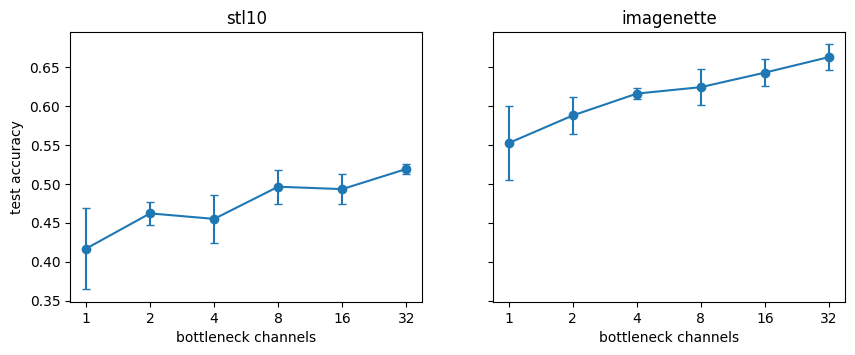

accuracy drop vs bottleneck 32


dataset,imagenette,stl10
bottleneck,,
1,0.1106,0.1025
2,0.0751,0.0571
4,0.0470,0.0642
8,0.0387,0.0228
16,0.0200,0.0259
32,0.0000,0.0000


smallest bottleneck within 1% of the widest: {'imagenette': 32, 'stl10': 32}


mean     std
dataset    bottleneck retina_layers cortex_layers                
imagenette 1          2             2              0.5526  0.0472
           2          1             2              0.5802  0.0127
                                    4              0.7109  0.0133
                      2             2              0.5881  0.0240
                                    4              0.6819  0.0127
           4          2             2              0.6162  0.0067
           8          2             2              0.6245  0.0230
           16         1             2              0.6448  0.0108
                                    4              0.7084  0.0090
                      2             2              0.6432  0.0177
                                    4              0.6843  0.0054
           32         2             2              0.6632  0.0162
stl10      1          2             2              0.4167  0.0525
           2          1             2              0.4712  0.0161
                                    4              0.5948  0.0186
                      2             2              0.4621  0.0152
                                    4              0.5851  0.0128
           4          2             2              0.4550  0.0304
           8          2             2              0.4964  0.0217
           16         1             2              0.5281  0.0283
                                    4              0.5722  0.0109
                      2             2              0.4933  0.0193
                                    4              0.5510  0.0109
           32         2             2              0.5192  0.0065

In [6]:
df = pd.read_csv(RESULTS_CSV)
if RERUNS_CSV.exists():  # collapsed runs are replaced by their rerun (lr / 3)
    rr = pd.read_csv(RERUNS_CSV)
    df = pd.concat([df.merge(rr[KEY], on=KEY, how='left', indicator=True).query("_merge == 'left_only'").drop(columns='_merge'),
                    rr.drop(columns='lr')], ignore_index=True)
keys = ['dataset', 'bottleneck', 'retina_layers', 'cortex_layers']
summary = df.groupby(keys).test_acc.agg(['mean', 'std']).round(4)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, ds in zip(axes, DATASETS):
    g = summary.xs((ds, 2, 2), level=['dataset', 'retina_layers', 'cortex_layers'])
    ax.errorbar(g.index, g['mean'], g['std'], marker='o', capsize=3)
    ax.set(xscale='log', xticks=BOTTLENECKS, xticklabels=BOTTLENECKS, title=ds, xlabel='bottleneck channels')
    ax.minorticks_off()
axes[0].set_ylabel('test accuracy')
plt.show()

# H3: accuracy drop w.r.t. the widest bottleneck, and the narrowest width within TOL of it.
TOL = 0.01
main = summary.xs((2, 2), level=['retina_layers', 'cortex_layers'])['mean'].unstack('dataset')
drop = (main.loc[BOTTLENECKS[-1]] - main).round(4)
print('accuracy drop vs bottleneck', BOTTLENECKS[-1])
display(drop)
print(f'smallest bottleneck within {TOL:.0%} of the widest:', (drop <= TOL).idxmax().to_dict())
summary


## Learned filters

Receptive field (RF) of each retina output channel (`retina_layers * 8 + 1` pixels wide): gradient of the channel's activation at the image centre with respect to the input, averaged over 256 natural images. This is the paper's linear RF estimate except for the probe: the paper uses a blank image, but in our networks most retina units are silent on a flat image (541 of the 702 sweep channels, 77%, have a zero gradient at a flat mid-gray image; `results/filters_blank_probe.csv`), so we average the gradient over natural images instead. The input is centred as in the models' forward pass, `(x - 0.5) / 0.25`, so that the units are probed at the operating point they were trained at. An earlier version of this notebook probed the retina without that centring (a bug, found when re-reading the paper); its outputs are kept in `results/filters_rawprobe.csv` and `results/control_filters_rawprobe.csv`, and every number below uses the corrected probe. Each RF is classified with two tools:

- **Orientation selectivity index (OSI)**, as in App. A of the paper: strongest response to a rectangular bar at the preferred orientation divided by the strongest response at the orthogonal one (about 1 for isotropic RFs, larger for oriented ones; the paper reports 1.56 for the retina output, 3.05 for the first cortical layer, 1.97 for random RFs).
- **Fit quality ($R^2$) of an isotropic difference of Gaussians (DoG) and of a Gabor**.

Label: `center-surround` if OSI < `OSI_THR` and the DoG fits well (not worse than the Gabor by more than `R2_TOL`); `oriented` if OSI >= `OSI_THR` and the Gabor fits better than the DoG; `dead` if the gradient is zero; `other` otherwise. Thresholds are set on synthetic filters only, before looking at learned ones.

In [7]:
def load_model(ds, cfg, seed):
    tag = f"{ds}_b{cfg['bottleneck']}_r{cfg['retina_layers']}_c{cfg['cortex_layers']}_s{seed}"
    model = RetinaCortexNet(1 if GRAYSCALE else 3, 10, **cfg)
    model.load_state_dict(torch.load(CKPT_DIR / f'{tag}.pt', map_location='cpu'))
    return model.to(DEVICE).eval()

def probe_images(ds, n=256):
    x = raw_splits(ds)[1][0]
    idx = torch.randperm(len(x), generator=torch.Generator().manual_seed(0))[:n]
    return x[idx].float().div(255).to(DEVICE)

def retina_rfs(model, images, size=IMG_SIZE):
    """Linear RF of each retina output channel at the image centre: gradient w.r.t. the input, averaged over the given images
    (natural images, or a flat image as the paper's blank-image probe). The input is centred exactly as in the models' forward pass,
    (x - 0.5) / 0.25, so that the units are probed at the operating point they were trained at."""
    n_conv = sum(isinstance(m, nn.Conv2d) for m in model.retina)
    c, h = size // 2, n_conv * (KERNEL - 1) // 2
    x = images.clone().requires_grad_(True)
    out = model.retina((x - 0.5) / 0.25)  # same input centring as RetinaCortexNet.forward / PaperNet.forward
    rfs = []
    for ch in range(out.shape[1]):
        g, = torch.autograd.grad(out[:, ch, c, c].sum(), x, retain_graph=True)
        rfs.append((g.mean(0).mean(0) )[c - h:c + h + 1, c - h:c + h + 1].cpu().numpy())
    return np.stack(rfs)

def plot_filters(rfs, labels=None, ncols=8, title=''):
    nrows = int(np.ceil(len(rfs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.5, nrows * 1.6), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for i, (ax, f) in enumerate(zip(axes.ravel(), rfs)):
        m = max(np.abs(f).max(), 1e-12)
        ax.imshow(f, cmap='RdBu', vmin=-m, vmax=m)
        if labels is not None:
            ax.set_title(labels[i], fontsize=7)
    fig.suptitle(title)
    plt.show()


In [8]:
OSI_THR, R2_MIN, R2_TOL = 2.0, 0.5, 0.05
LABELS = ['center-surround', 'oriented', 'other', 'dead']

def _grid(n):
    yy, xx = np.mgrid[:n, :n].astype(float) - (n - 1) / 2
    return xx, yy

def orientation_index(rf, n_orient=12, widths=(1, 2, 3, 4, 5, 6)):
    """Paper App. A: best bar response at the preferred orientation / best response at the orthogonal one."""
    n = rf.shape[0]
    xx, yy = _grid(n)
    offsets = np.arange(-(n // 2), n // 2 + 1)
    resp = np.zeros((len(widths), n_orient, len(offsets)))
    for j in range(n_orient):
        th = j * np.pi / n_orient
        u = xx * np.cos(th) + yy * np.sin(th)
        for i, w in enumerate(widths):
            bars = np.abs(u[None] - offsets[:, None, None]) <= w / 2
            resp[i, j] = np.abs(bars.reshape(len(offsets), -1) @ rf.ravel())
    i, j, _ = np.unravel_index(resp.argmax(), resp.shape)
    s = resp[i].max(axis=1)
    perp = s[(j + n_orient // 2) % n_orient]
    return s[j] / max(perp, 1e-8 * s[j]), j * np.pi / n_orient

def _dog(p, xx, yy):
    x0, y0, sc, ss, a, k = p
    r2 = (xx - x0) ** 2 + (yy - y0) ** 2
    return a * (np.exp(-r2 / (2 * sc ** 2)) - k * np.exp(-r2 / (2 * ss ** 2)))

def _gabor(p, xx, yy):
    x0, y0, sx, sy, th, f, ph, a = p
    u = (xx - x0) * np.cos(th) + (yy - y0) * np.sin(th)
    v = -(xx - x0) * np.sin(th) + (yy - y0) * np.cos(th)
    return a * np.exp(-u ** 2 / (2 * sx ** 2) - v ** 2 / (2 * sy ** 2)) * np.cos(2 * np.pi * f * u + ph)

def _best_r2(fn, starts, lo, hi, rf, xx, yy):
    sst = ((rf - rf.mean()) ** 2).sum()
    best = -np.inf
    for p0 in starts:
        res = least_squares(lambda p: (fn(p, xx, yy) - rf).ravel(), p0, bounds=(lo, hi), max_nfev=200)
        best = max(best, 1 - (2 * res.cost) / sst)
    return best

def filter_stats(rf):
    n = rf.shape[0]
    if np.abs(rf).max() < 1e-10:
        return dict(osi=np.nan, r2_dog=np.nan, r2_gabor=np.nan, label='dead')
    rf = rf / np.abs(rf).max()
    xx, yy = _grid(n)
    osi, th = orientation_index(rf)
    sign = 1.0 if rf.flat[np.abs(rf).argmax()] > 0 else -1.0
    s = n / 10
    r2_dog = _best_r2(
        _dog, [[0, 0, sc, 2.5 * sc, sign, 0.8] for sc in (s, 1.6 * s)],
        [-n / 4, -n / 4, 0.7, 0.7, -3, 0.2], [n / 4, n / 4, n / 2, n, 3, 2], rf, xx, yy)
    r2_gabor = _best_r2(
        _gabor, [[0, 0, n / 5, n / 5, t, f, ph, sign] for t in (th, th + np.pi / 2) for f in (0.1, 0.2) for ph in (0, np.pi / 2)],
        [-n / 3, -n / 3, 0.7, 0.7, -2 * np.pi, 0.05, -2 * np.pi, -3], [n / 3, n / 3, n, n, 2 * np.pi, 0.5, 2 * np.pi, 3], rf, xx, yy)
    if osi < OSI_THR and r2_dog >= R2_MIN and r2_dog >= r2_gabor - R2_TOL:
        label = 'center-surround'
    elif osi >= OSI_THR and r2_gabor >= R2_MIN and r2_gabor > r2_dog:
        label = 'oriented'
    else:
        label = 'other'
    return dict(osi=osi, r2_dog=r2_dog, r2_gabor=r2_gabor, label=label)

def filter_type(kernel_2d):
    return filter_stats(np.asarray(kernel_2d, dtype=float))['label']


In [9]:
# Sanity check of the classifier on synthetic 17x17 filters (ground truth known), with 10% additive noise.
rng = np.random.default_rng(0)
xx, yy = _grid(17)
def synth(kind):
    if kind == 'center-surround':
        sc = rng.uniform(1.5, 3)
        rf = _dog([rng.uniform(-1, 1), rng.uniform(-1, 1), sc, sc * rng.uniform(1.8, 3), rng.choice([-1, 1]), rng.uniform(0.6, 1.0)], xx, yy)
    elif kind == 'oriented':
        rf = _gabor([rng.uniform(-1, 1), rng.uniform(-1, 1), rng.uniform(2.5, 4.5), rng.uniform(2.5, 4.5), rng.uniform(0, np.pi),
                     rng.uniform(0.08, 0.2), rng.uniform(0, 2 * np.pi), 1], xx, yy)
    else:
        return rng.standard_normal((17, 17))
    return rf / np.abs(rf).max() + 0.1 * rng.standard_normal((17, 17))

check = pd.DataFrame([dict(truth=k, pred=filter_type(synth(k))) for k in ['center-surround', 'oriented', 'noise'] for _ in range(40)])
pd.crosstab(check.truth, check.pred)


pred,center-surround,oriented,other
truth,,,
center-surround,40,0,0
noise,0,0,40
oriented,0,40,0


In [10]:
def analyse_filters(only=None):
    rows = []
    for ds in DATASETS:
        images = probe_images(ds)
        for cfg, s in itertools.product(CONFIGS, SEEDS):
            if only is not None and (ds, cfg['bottleneck'], cfg['retina_layers'], cfg['cortex_layers'], s) not in only:
                continue
            for ch, rf in enumerate(retina_rfs(load_model(ds, cfg, s), images)):
                rows.append(dict(dataset=ds, seed=s, channel=ch, **cfg, **filter_stats(rf)))
    return pd.DataFrame(rows)

if FILTERS_CSV.exists():
    filters_df = pd.read_csv(FILTERS_CSV)
    if RERUNS_CSV.exists():  # refresh only the networks that were retrained after a collapse
        stale = set(map(tuple, pd.read_csv(RERUNS_CSV)[KEY].values))
        fresh = analyse_filters(stale)
        old = filters_df.merge(fresh[KEY].drop_duplicates(), on=KEY, how='left', indicator=True)
        filters_df = pd.concat([old.query("_merge == 'left_only'").drop(columns='_merge'), fresh], ignore_index=True)
        filters_df.to_csv(FILTERS_CSV, index=False)
else:
    filters_df = analyse_filters()
    filters_df.to_csv(FILTERS_CSV, index=False)
filters_df.groupby('label').size()


label
center-surround     22
dead                94
oriented           270
other              316
dtype: int64

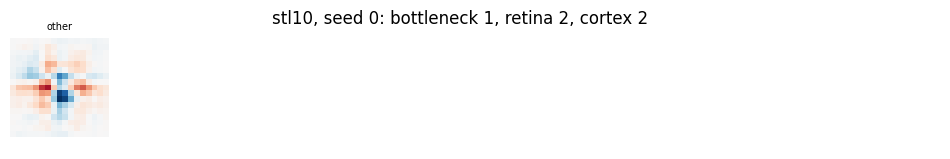

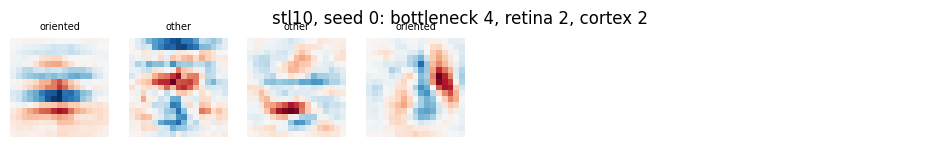

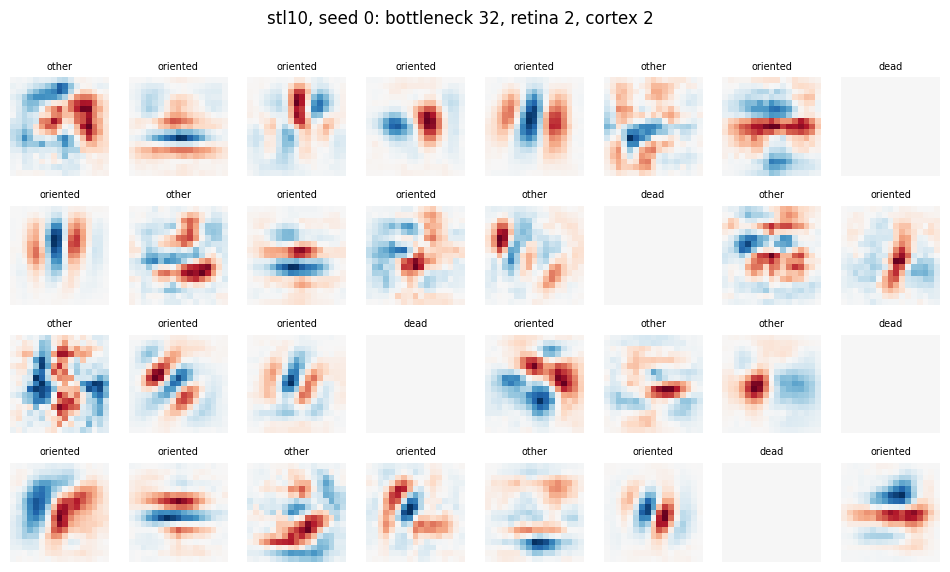

In [11]:
def show_rfs(ds, cfg, seed=0):
    rfs = retina_rfs(load_model(ds, cfg, seed), probe_images(ds))
    labels = [filter_type(rf) for rf in rfs]
    plot_filters(rfs, labels, title=f"{ds}, seed {seed}: bottleneck {cfg['bottleneck']}, retina {cfg['retina_layers']}, cortex {cfg['cortex_layers']}")

for b in (1, 4, 32):
    show_rfs(DATASETS[0], dict(bottleneck=b, retina_layers=2, cortex_layers=2))


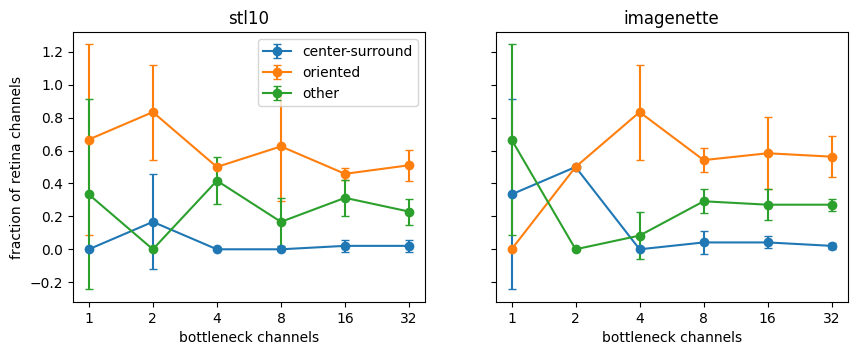

label                                             center-surround        \
                                                             mean   std   
dataset    bottleneck retina_layers cortex_layers                         
imagenette 1          2             2                        0.33  0.58   
           2          1             2                        0.00  0.00   
                                    4                        0.00  0.00   
                      2             2                        0.50  0.00   
                                    4                        0.17  0.29   
           4          2             2                        0.00  0.00   
           8          2             2                        0.04  0.07   
           16         1             2                        0.02  0.04   
                                    4                        0.00  0.00   
                      2             2                        0.04  0.04   
                                    4                        0.08  0.04   
           32         2             2                        0.02  0.02   
stl10      1          2             2                        0.00  0.00   
           2          1             2                        0.00  0.00   
                                    4                        0.00  0.00   
                      2             2                        0.17  0.29   
                                    4                        0.17  0.29   
           4          2             2                        0.00  0.00   
           8          2             2                        0.00  0.00   
           16         1             2                        0.00  0.00   
                                    4                        0.00  0.00   
                      2             2                        0.02  0.04   
                                    4                        0.04  0.04   
           32         2             2                        0.02  0.04   

label                                             oriented       other        \
                                                      mean   std  mean   std   
dataset    bottleneck retina_layers cortex_layers                              
imagenette 1          2             2                 0.00  0.00  0.67  0.58   
           2          1             2                 0.00  0.00  1.00  0.00   
                                    4                 0.00  0.00  1.00  0.00   
                      2             2                 0.50  0.00  0.00  0.00   
                                    4                 0.50  0.00  0.33  0.29   
           4          2             2                 0.83  0.29  0.08  0.14   
           8          2             2                 0.54  0.07  0.29  0.07   
           16         1             2                 0.31  0.12  0.67  0.13   
                                    4                 0.00  0.00  1.00  0.00   
                      2             2                 0.58  0.22  0.27  0.10   
                                    4                 0.33  0.24  0.38  0.11   
           32         2             2                 0.56  0.12  0.27  0.04   
stl10      1          2             2                 0.67  0.58  0.33  0.58   
           2          1             2                 0.00  0.00  1.00  0.00   
                                    4                 0.00  0.00  1.00  0.00   
                      2             2                 0.83  0.29  0.00  0.00   
                                    4                 0.50  0.50  0.17  0.29   
           4          2             2                 0.50  0.00  0.42  0.14   
           8          2             2                 0.62  0.33  0.17  0.14   
           16         1             2                 0.19  0.06  0.81  0.06   
                                    4                 0.06  0.06  0.94  0.06   
                      2             2                 

In [12]:
per_seed = (filters_df.groupby(keys + ['seed']).label.value_counts(normalize=True).unstack(fill_value=0)
            .reindex(columns=LABELS, fill_value=0))
per_seed['osi'] = filters_df.groupby(keys + ['seed']).osi.mean()
per_cfg = per_seed.groupby(keys).agg(['mean', 'std'])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, ds in zip(axes, DATASETS):
    g = per_cfg.xs((ds, 2, 2), level=['dataset', 'retina_layers', 'cortex_layers'])
    for lab in LABELS[:3]:
        ax.errorbar(g.index, g[(lab, 'mean')], g[(lab, 'std')], marker='o', capsize=3, label=lab)
    ax.set(xscale='log', xticks=BOTTLENECKS, xticklabels=BOTTLENECKS, title=ds, xlabel='bottleneck channels')
    ax.minorticks_off()
axes[0].set_ylabel('fraction of retina channels')
axes[0].legend()
plt.show()

per_cfg.round(2)


In [13]:
# Depth ablation at bottleneck 2 and 16 (mean over seeds): accuracy, share of center-surround / oriented channels, mean OSI.
depth = (summary['mean'].rename('acc').to_frame()
         .join(per_seed.groupby(keys)[['center-surround', 'oriented', 'osi']].mean())
         .loc[lambda d: d.index.get_level_values('bottleneck').isin([2, 16])]
         .sort_index(level=['dataset', 'bottleneck', 'retina_layers', 'cortex_layers']).round(3))
depth


acc  center-surround  \
dataset    bottleneck retina_layers cortex_layers                           
imagenette 2          1             2              0.580            0.000   
                                    4              0.711            0.000   
                      2             2              0.588            0.500   
                                    4              0.682            0.167   
           16         1             2              0.645            0.021   
                                    4              0.708            0.000   
                      2             2              0.643            0.042   
                                    4              0.684            0.083   
stl10      2          1             2              0.471            0.000   
                                    4              0.595            0.000   
                      2             2              0.462            0.167   
                                    4              0.585            0.167   
           16         1             2              0.528            0.000   
                                    4              0.572            0.000   
                      2             2              0.493            0.021   
                                    4              0.551            0.042   

                                                   oriented    osi  
dataset    bottleneck retina_layers cortex_layers                   
imagenette 2          1             2                 0.000  2.313  
                                    4                 0.000  2.624  
                      2             2                 0.500  2.507  
                                    4                 0.500  2.453  
           16         1             2                 0.312  3.014  
                                    4                 0.000  2.270  
                      2             2                 0.583  3.663  
                                    4                 0.333  2.156  
stl10      2          1             2                 0.000  1.777  
                                    4                 0.000  1.945  
                      2             2                 0.833  3.699  
                                    4                 0.500  2.822  
           16         1             2                 0.188  3.439  
                                    4                 0.062  2.628  
                      2             2                 0.458  3.937  
                                    4                 0.292  2.977

## Retina filters without labels

The `center-surround` / `oriented` labels depend on thresholds and on two parametric fits. This section looks at the quantity they are built on, the OSI of the non-dead retina channels, so that the reading of H1 and H2 does not rest on the labels alone. Label counts are given instead of percentages because narrow bottlenecks have very few channels per cell (3 seeds x bottleneck width). Reference values from the paper: OSI 1.56 for the retina output, 3.05 for the first cortical layer, 1.97 for random filters.

center-surround  oriented  \
dataset    bottleneck retina_layers cortex_layers                              
imagenette 1          2             2                            1         0   
           2          1             2                            0         0   
                                    4                            0         0   
                      2             2                            3         3   
                                    4                            1         3   
           4          2             2                            0        10   
           8          2             2                            1        13   
           16         1             2                            1        15   
                                    4                            0         0   
                      2             2                            2        28   
                                    4                            4        16   
           32         2             2                            2        54   
stl10      1          2             2                            0         2   
           2          1             2                            0         0   
                                    4                            0         0   
                      2             2                            1         5   
                                    4                            1         3   
           4          2             2                            0         6   
           8          2             2                            0        15   
           16         1             2                            0         9   
                                    4                            0         3   
                      2             2                            1        22   
                                    4                            2        14   
           32         2             2                            2        49   

                                                   other  dead  channels  \
dataset    bottleneck retina_layers cortex_layers                          
imagenette 1          2             2                  2     0         3   
           2          1             2                  6     0         6   
                                    4                  6     0         6   
                      2             2                  0     0         6   
                                    4                  2     0         6   
           4          2             2                  1     1        12   
           8          2             2                  7     3        24   
           16         1             2                 32     0        48   
                                    4                 48     0        48   
                      2             2                 13     5        48   
                                    4                 18    10        48   
           32         2             2                 26    14        96   
stl10      1          2             2                  1     0         3   
           2          1             2                  6     0         6   
                                    4                  6     0         6   
                      2             2                  0     0         6   
                                    4                  1     1         6   
           4          2             2                  5     1        12   
           8          2             2                  4     5        24   
           16         1             2                 39     0        48   
                                    4                 45     0        48   
                      2             2                 15    10        48   
                                    4                 11    21        48   
           32         2             2                 22    23        

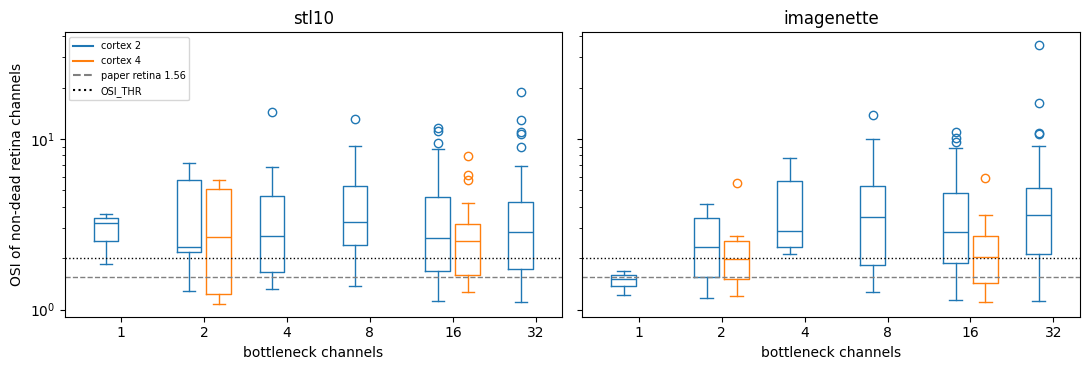

In [14]:
# Label counts (not percentages) and OSI of the live retina channels for every configuration, plus the OSI distribution per bottleneck.
live = filters_df[filters_df.label != 'dead']
counts = filters_df.groupby(keys).label.value_counts().unstack(fill_value=0).reindex(columns=LABELS, fill_value=0)
counts['channels'] = counts.sum(axis=1)
osi_tab = live.groupby(keys).osi.agg(live='count', osi_median='median')
osi_tab['share_osi_lt_2'] = live.groupby(keys).osi.apply(lambda x: (x < OSI_THR).mean())  # share of isotropic-looking channels
display(counts.join(osi_tab).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, ds in zip(axes, DATASETS):
    d = live[(live.dataset == ds) & (live.retina_layers == 2)]
    for j, b in enumerate(BOTTLENECKS):
        for cl, off, col in ((2, -0.18, 'C0'), (4, 0.18, 'C1')):  # cortex depth 4 exists only for bottleneck 2 and 16
            v = d[(d.bottleneck == b) & (d.cortex_layers == cl)].osi
            if len(v):
                ax.boxplot(v, positions=[j + off], widths=0.3, boxprops=dict(color=col), medianprops=dict(color=col),
                           whiskerprops=dict(color=col), capprops=dict(color=col), flierprops=dict(markeredgecolor=col))
    ax.axhline(1.56, ls='--', color='gray', lw=1)  # retina OSI of the paper
    ax.axhline(OSI_THR, ls=':', color='k', lw=1)   # threshold of the `oriented` label
    ax.set(xticks=range(len(BOTTLENECKS)), xticklabels=BOTTLENECKS, xlabel='bottleneck channels', title=ds, yscale='log')
axes[0].set_ylabel('OSI of non-dead retina channels')
axes[0].legend(handles=[plt.Line2D([], [], color='C0', label='cortex 2'), plt.Line2D([], [], color='C1', label='cortex 4'),
                        plt.Line2D([], [], color='gray', ls='--', label='paper retina 1.56'), plt.Line2D([], [], color='k', ls=':', label='OSI_THR')], fontsize=7)
plt.tight_layout()
plt.show()

## Positive control: the paper's own setup

H1 was not reproduced, and the sweep differs from the paper in several ways at once (STL-10 / Imagenette at 96x96 with 4,500-8,500 training images, max-pooling and a global-average-pool head instead of a flattened FC 1024, our RF probe). Without a run in the paper's own setup it is not possible to say whether the non-reproduction comes from those differences or from the training and analysis pipeline (RF probe, DoG/Gabor labels, thresholds). This control trains the architecture of Lindsey et al. on their data and analyses it with exactly the same code as the main sweep.

**Setup.** Grayscale CIFAR-10 at 32x32 (45,000 training images, 5,000 validation, official test set), retina of 2 convolutions with `bottleneck` channels at the output, cortex of 2 or 4 convolutions, **no pooling**, flatten, FC 1024, FC 10. Everything else as in the main sweep (9x9 kernels, 32 channels, Glorot, RMSProp lr 1e-3, 20 epochs, batch 32, best-validation checkpoint, horizontal flip, collapse rule). Bottlenecks 1, 4 and 32, cortex depth 2 and 4, 3 seeds. The retina receptive fields are computed with two probes: the gradient averaged over 256 natural test images (the probe of the main sweep) and the gradient at a flat mid-gray image (the paper's blank-image probe).

**Prediction and decision rule (written before running).**
- P1 (the pipeline can see the effect): at bottleneck 1 and 4 with cortex 4 at least 30% of the live retina channels are labelled `center-surround`, against less than 10% at bottleneck 32 with cortex 2. P1 is judged with the blank-image probe (the paper's) and with the natural-image probe (the sweep's). A smoke test before the run showed that after 1 epoch every retina channel is silent on a flat image, as already seen in the main sweep, so the blank-image probe may leave few live channels: **if fewer than 30% of the channels are live under the blank probe, that probe is not informative and P1 is judged on the natural-image probe alone** (this rule was added after the smoke test and before the control was run).
- If P1 holds, the pipeline detects the effect where the paper reports it, and the missing effect on STL-10 and Imagenette is attributable to the differences in data and architecture (not tested individually).
- If P1 fails but the share of channels with OSI < 2 is clearly larger at narrow bottleneck and deep cortex than at the wide one, the `center-surround` label is too strict, and the OSI-based reading of the main sweep is the one to report.
- If neither holds, the paper's result is not obtained in its own setup with this pipeline, and the non-reproduction on STL-10 and Imagenette cannot be attributed to the data or the architecture: it would point to the pipeline (or to a fragile result), and H1 would have to be reported as untested rather than as not reproduced.
- P2: the natural-image probe gives the same ordering of the configurations as the blank-image probe.

In [15]:
# Positive control: the paper's architecture (no pooling, flatten + FC 1024) on grayscale CIFAR-10 at 32x32, same recipe and analysis as the sweep.
CTRL_BOTTLENECKS, CTRL_CORTEX, CTRL_SIZE = [1, 4, 32], [2, 4], 32
CTRL_CSV, CTRL_CKPT = Path('results/control_cifar10.csv'), Path('checkpoints_cifar')
CTRL_COLLAPSE_VAL, CTRL_RERUN_LR = 0.2, LR / 3  # same collapse rule as the main sweep

class PaperNet(nn.Module):
    # Lindsey et al.: retina (2 convs, `bottleneck` channels at the output), cortex (`cortex_layers` convs), no pooling, FC 1024, FC 10
    def __init__(self, bottleneck, cortex_layers, size=CTRL_SIZE, in_ch=1, num_classes=10, retina_layers=2, kernel=KERNEL, width=32):
        super().__init__()
        pad = kernel // 2
        retina, c = [], in_ch
        for i in range(retina_layers):
            out = bottleneck if i == retina_layers - 1 else width
            retina += [nn.Conv2d(c, out, kernel, padding=pad), nn.ReLU()]
            c = out
        cortex = []
        for _ in range(cortex_layers):
            cortex += [nn.Conv2d(c, width, kernel, padding=pad), nn.ReLU()]
            c = width
        self.retina, self.cortex = nn.Sequential(*retina), nn.Sequential(*cortex)
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(width * size * size, 1024), nn.ReLU(), nn.Linear(1024, num_classes))
        for m in self.modules():  # Glorot-uniform and zero biases, as in the main sweep
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.head(self.cortex(self.retina((x - 0.5) / 0.25)))  # same input centring as the main sweep

_CIFAR = {}

def cifar_splits():
    # decode once: grayscale, uint8 (train 50,000 / test 10,000)
    if not _CIFAR:
        tf = T.Compose([T.Grayscale(), T.PILToTensor()])
        for name, train_split in (('train', True), ('test', False)):
            ds = torchvision.datasets.CIFAR10(DATA_ROOT / 'cifar10', train=train_split, transform=tf, download=True)
            _CIFAR[name] = (torch.stack([x for x, _ in ds]), torch.tensor(ds.targets))
    return _CIFAR['train'], _CIFAR['test']

def cifar_loaders(seed):
    # 10% of the training set held out for validation (split depends on the seed), flip augmentation only, as in the sweep
    (x_tr, y_tr), (x_te, y_te) = cifar_splits()
    n_val = len(y_tr) // 10
    perm = torch.randperm(len(y_tr), generator=torch.Generator().manual_seed(seed))
    tr, va = perm[n_val:], perm[:n_val]
    return GPULoader(x_tr[tr], y_tr[tr], True, flip=True), GPULoader(x_tr[va], y_tr[va], False), GPULoader(x_te, y_te, False)

def ctrl_run(bottleneck, cortex_layers, seed, lr):
    global LR
    lr_orig, LR = LR, lr
    try:
        set_seed(seed)
        train_dl, val_dl, test_dl = cifar_loaders(seed)
        model = PaperNet(bottleneck, cortex_layers).to(DEVICE)
        val_acc = train(model, train_dl, val_dl)
        return model, val_acc, evaluate(model, test_dl)
    finally:
        LR = lr_orig

CTRL_CKPT.mkdir(exist_ok=True)
CTRL_CSV.parent.mkdir(exist_ok=True)
for b, cl, s in itertools.product(CTRL_BOTTLENECKS, CTRL_CORTEX, SEEDS):
    tag = f'cifar10_b{b}_c{cl}_s{s}'
    if (CTRL_CKPT / f'{tag}.pt').exists():
        continue
    t0 = time.time()
    model, val_acc, test_acc = ctrl_run(b, cl, s, LR)
    first = None
    if val_acc < CTRL_COLLAPSE_VAL:  # collapsed to chance: retrain once with lr / 3, keep the first result in the CSV
        first = val_acc
        model, val_acc, test_acc = ctrl_run(b, cl, s, CTRL_RERUN_LR)
    torch.save(model.state_dict(), CTRL_CKPT / f'{tag}.pt')
    row = dict(dataset='cifar10', bottleneck=b, cortex_layers=cl, seed=s, val_acc=val_acc, test_acc=test_acc, first_val_acc=first, time_s=time.time() - t0)
    pd.DataFrame([row]).to_csv(CTRL_CSV, mode='a', header=not CTRL_CSV.exists(), index=False)

In [16]:
# Retina receptive fields of the control networks with two probes (natural images; flat mid-gray image = the paper's blank-image probe), then the same labels as the sweep.
CTRL_FILTERS_CSV = Path('results/control_filters.csv')

def ctrl_model(b, cl, s):
    model = PaperNet(b, cl)
    model.load_state_dict(torch.load(CTRL_CKPT / f'cifar10_b{b}_c{cl}_s{s}.pt', map_location='cpu'))
    return model.to(DEVICE).eval()

if CTRL_FILTERS_CSV.exists():
    ctrl_filters = pd.read_csv(CTRL_FILTERS_CSV)
else:
    nat = cifar_splits()[1][0][torch.randperm(10000, generator=torch.Generator().manual_seed(0))[:256]].float().div(255).to(DEVICE)
    blank = torch.full((1, 1, CTRL_SIZE, CTRL_SIZE), 0.5, device=DEVICE)
    rows = []
    for b, cl, s in itertools.product(CTRL_BOTTLENECKS, CTRL_CORTEX, SEEDS):
        model = ctrl_model(b, cl, s)
        for probe, imgs in (('natural', nat), ('blank', blank)):
            for ch, rf in enumerate(retina_rfs(model, imgs, size=CTRL_SIZE)):
                rows.append(dict(probe=probe, seed=s, channel=ch, bottleneck=b, cortex_layers=cl, **filter_stats(rf)))
    ctrl_filters = pd.DataFrame(rows)
    ctrl_filters.to_csv(CTRL_FILTERS_CSV, index=False)
ctrl_filters.groupby(['probe', 'label']).size().unstack(fill_value=0)

label,center-surround,dead,oriented,other
probe,,,,
blank,6,207,3,6
natural,7,149,27,39


test accuracy (mean, std over seeds):


mean    std  count
bottleneck cortex_layers                     
1          2              0.672  0.004      3
           4              0.652  0.079      3
4          2              0.605  0.024      3
           4              0.555  0.022      3
32         2              0.594  0.021      3
           4              0.573  0.092      3

runs that collapsed and were retrained: 6


center-surround  oriented  other  dead  \
probe   bottleneck cortex_layers                                           
blank   1          2                            1         0      2     0   
                   4                            0         2      1     0   
        4          2                            2         0      0    10   
                   4                            2         0      1     9   
        32         2                            1         0      0    95   
                   4                            0         1      2    93   
natural 1          2                            1         0      2     0   
                   4                            0         1      2     0   
        4          2                            2         0      2     8   
                   4                            2         0      2     8   
        32         2                            1         4      4    87   
                   4                            1        22     27    46   

                                  channels  live  osi_median  share_osi_lt_2  \
probe   bottleneck cortex_layers                                               
blank   1          2                     3     3        1.36            0.67   
                   4                     3     3        2.09            0.33   
        4          2                    12     2        1.67            1.00   
                   4                    12     3        1.45            1.00   
        32         2                    96     1        1.34            1.00   
                   4                    96     3        2.14            0.33   
natural 1          2                     3     3        1.25            0.67   
                   4                     3     3        2.31            0.33   
        4          2                    12     4        1.58            0.75   
                   4                    12     4        1.85            0.50   
        32         2                    96     9        2.44            0.44   
                   4                    96    50        2.55            0.36   

                                  share_center_surround  
probe   bottleneck cortex_layers                         
blank   1          2                               0.33  
                   4                               0.00  
        4          2                               1.00  
                   4                               0.67  
        32         2                               1.00  
                   4                               0.00  
natural 1          2                               0.33  
                   4                               0.00  
        4          2                               0.50  
                   4                               0.50  
        32         2                               0.11  
                   4                               0.02

blank probe, live channels 15 of 222
  bottleneck <= 4, cortex 4: center-surround 2 of 6 live channels
  bottleneck 32, cortex 2:   center-surround 1 of 1 live channels
natural probe, live channels 73 of 222
  bottleneck <= 4, cortex 4: center-surround 2 of 7 live channels
  bottleneck 32, cortex 2:   center-surround 1 of 9 live channels


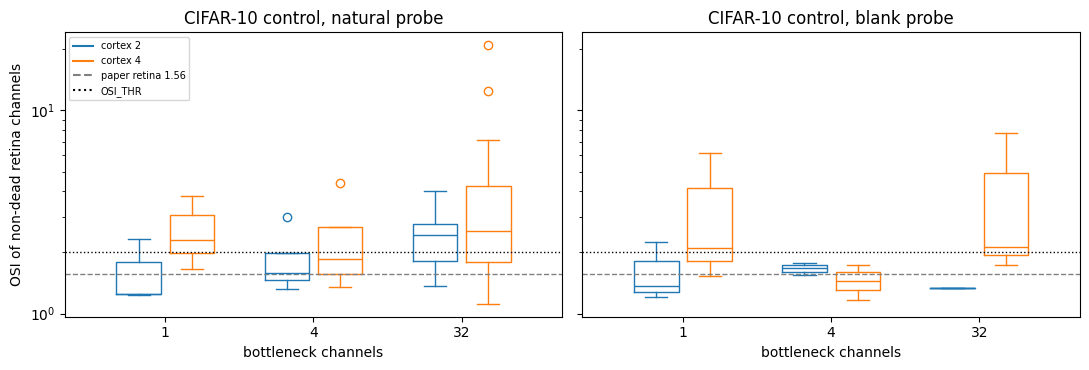

In [17]:
# Control analysis: accuracy, label counts and OSI per configuration and probe; P1 of the decision rule.
ctrl = pd.read_csv(CTRL_CSV)
print('test accuracy (mean, std over seeds):')
display(ctrl.groupby(['bottleneck', 'cortex_layers']).test_acc.agg(['mean', 'std', 'count']).round(3))
print('runs that collapsed and were retrained:', int(ctrl.first_val_acc.notna().sum()))

ck = ['probe', 'bottleneck', 'cortex_layers']
live_c = ctrl_filters[ctrl_filters.label != 'dead']
ctrl_counts = ctrl_filters.groupby(ck).label.value_counts().unstack(fill_value=0).reindex(columns=LABELS, fill_value=0)
ctrl_counts['channels'] = ctrl_counts.sum(axis=1)
ctrl_osi = live_c.groupby(ck).osi.agg(live='count', osi_median='median')
ctrl_osi['share_osi_lt_2'] = live_c.groupby(ck).osi.apply(lambda x: (x < OSI_THR).mean())
ctrl_tab = ctrl_counts.join(ctrl_osi)
ctrl_tab['share_center_surround'] = ctrl_tab['center-surround'] / ctrl_tab.live
display(ctrl_tab.round(2))

# P1: share of center-surround channels among the live ones, narrow + deep against wide + shallow, for both probes (and how many channels are live)
for probe in ['blank', 'natural']:
    pr = ctrl_tab.xs(probe)
    nd, ws = pr.loc[[(b, 4) for b in CTRL_BOTTLENECKS if b <= 4]], pr.loc[[(32, 2)]]
    print(f'{probe} probe, live channels {pr.live.sum()} of {pr.channels.sum()}')
    print(f'  bottleneck <= 4, cortex 4: center-surround {nd["center-surround"].sum()} of {nd.live.sum()} live channels')
    print(f'  bottleneck 32, cortex 2:   center-surround {ws["center-surround"].sum()} of {ws.live.sum()} live channels')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, probe in zip(axes, ['natural', 'blank']):
    d = live_c[live_c.probe == probe]
    for j, b in enumerate(CTRL_BOTTLENECKS):
        for cl, off, col in ((2, -0.18, 'C0'), (4, 0.18, 'C1')):
            v = d[(d.bottleneck == b) & (d.cortex_layers == cl)].osi
            if len(v):
                ax.boxplot(v, positions=[j + off], widths=0.3, boxprops=dict(color=col), medianprops=dict(color=col),
                           whiskerprops=dict(color=col), capprops=dict(color=col), flierprops=dict(markeredgecolor=col))
    ax.axhline(1.56, ls='--', color='gray', lw=1)
    ax.axhline(OSI_THR, ls=':', color='k', lw=1)
    ax.set(xticks=range(len(CTRL_BOTTLENECKS)), xticklabels=CTRL_BOTTLENECKS, xlabel='bottleneck channels', title=f'CIFAR-10 control, {probe} probe', yscale='log')
axes[0].set_ylabel('OSI of non-dead retina channels')
axes[0].legend(handles=[plt.Line2D([], [], color='C0', label='cortex 2'), plt.Line2D([], [], color='C1', label='cortex 4'),
                        plt.Line2D([], [], color='gray', ls='--', label='paper retina 1.56'), plt.Line2D([], [], color='k', ls=':', label='OSI_THR')], fontsize=7)
plt.tight_layout()
plt.show()

### Positive control: findings

Grayscale CIFAR-10 at 32x32, architecture of Lindsey et al. (no pooling, FC 1024), 18 runs (bottleneck 1, 4, 32; cortex 2, 4; 3 seeds), analysed with the code of the main sweep and the corrected RF probe.

- **The paper's recipe is fragile in our hands.** Test accuracy is 0.56-0.67. 6 of 18 runs collapsed to chance at the first attempt (5 of them at bottleneck 1) and were retrained with lr / 3 as in the sweep. 67% of the retina channels are dead under the natural-image probe (149 of 222; 13% in the main sweep) and 93% under the flat-image probe (207 of 222; 77% in the sweep). Only 73 channels are live under the natural probe and 15 under the flat one.
- **At the paper's headline configuration the control reproduces the number.** Bottleneck 1 and cortex depth 2 (Fig. 2B and 4 of the paper): the three seeds give one live retina channel each with OSI 1.24, 1.25 and 2.32 under the natural probe (mean 1.60) and 1.20, 1.36 and 2.26 under the flat probe (mean 1.61), against 1.56 (+- 0.22) in the paper (App. A); one of the three channels is labelled `center-surround`, the other two `other`.
- **P1 is not met as written.** Only the natural probe leaves at least 30% of the channels live (73 of 222), so P1 is judged on it. Bottleneck 1 and 4 with cortex 4 have 2 of 7 live channels labelled `center-surround` (29%, just under the 30% bar), and bottleneck 32 with cortex 2 has 1 of 9 (11%, just above the 10% bar). The second branch of the rule (share of channels with OSI < 2 clearly larger at narrow bottleneck and deep cortex than at the wide one) does not hold either: 3 of 7 against 4 of 9. By the rule as written the control therefore falls in the third branch: it does not license attributing the missing effect on STL-10 and Imagenette to the data or the architecture.
- **Post-hoc view at the paper's cortex depth.** The rule was written for cortex 4 following our hypothesis 1, but the paper states that the RF geometry does not depend qualitatively on the cortex depth and shows its results at depth 2. At cortex 2, 5 of 7 live channels at bottleneck 1 and 4 have OSI < 2 (median 1.50) against 4 of 9 at bottleneck 32 (median 2.44): the direction of the paper, on 7 and 9 channels. At cortex 4 there is no contrast (median OSI 2.31 at bottleneck 1, 1.85 at bottleneck 4, 2.55 at bottleneck 32). This view was chosen after seeing the data and is not a confirmation.
- **Reading.** The control reproduces the paper's headline value in the paper's own setup, so the analysis pipeline can return the effect, but it is too underpowered (few live channels, collapses, low accuracy) to say which of the differences between the setups (data size, resolution, pooling and GAP head) is responsible. H1 is therefore reported as *not reproduced in the reduced setting*, with that attribution left as a hypothesis.

## Cortex depth grid (paper Fig. 1D and 3A)

The paper varies the depth of the cortex from 0 to 4 convolutional layers; the main sweep only has depth 2, plus depth 4 at bottleneck 2 and 16. This section trains bottleneck 1, 4 and 32 at cortex depth 1, 3 and 4 (depth 2 comes from the main sweep) with exactly the recipe and the collapse rule of the sweep, on both datasets and 3 seeds (54 runs). Results and checkpoints go to separate files (`results/depth_grid.csv`, `checkpoints_depth/`), so the statistics of the main sweep above are untouched. Depth 0 is not run: with a global-average-pool head it would classify from a global average of at most 32 retinal channels, which is not the paper's architecture (flatten + dense layers).

**Prediction (from the paper, Fig. 1D, written before running).** Test accuracy increases with the cortex depth at every bottleneck and with the bottleneck width at every depth, on both datasets.

In [18]:
# Cortex depth grid: bottleneck 1, 4, 32 at cortex depth 1, 3, 4; same recipe and collapse rule as the main sweep, separate CSV and checkpoints.
DEPTH_CSV, DEPTH_CKPT = Path('results/depth_grid.csv'), Path('checkpoints_depth')
DEPTH_CONFIGS = [dict(bottleneck=b, retina_layers=2, cortex_layers=cl) for b in (1, 4, 32) for cl in (1, 3, 4)]
DEPTH_COLLAPSE_VAL, DEPTH_RERUN_LR = 0.2, LR / 3  # same collapse rule as the sweep: retrain once with lr / 3
DEPTH_CKPT.mkdir(exist_ok=True)

for ds, cfg, s in itertools.product(DATASETS, DEPTH_CONFIGS, SEEDS):
    tag = f"{ds}_b{cfg['bottleneck']}_r{cfg['retina_layers']}_c{cfg['cortex_layers']}_s{s}"
    if (DEPTH_CKPT / f'{tag}.pt').exists():
        continue
    t0 = time.time()
    model, metrics = run_one(ds, cfg, s)
    first = None
    if metrics['val_acc'] < DEPTH_COLLAPSE_VAL:  # collapsed to chance: retrain once with lr / 3, keep the first validation accuracy
        first = metrics['val_acc']
        lr_orig, LR = LR, DEPTH_RERUN_LR
        try:
            model, metrics = run_one(ds, cfg, s)
        finally:
            LR = lr_orig
    torch.save(model.state_dict(), DEPTH_CKPT / f'{tag}.pt')
    row = dict(dataset=ds, seed=s, time_s=time.time() - t0, **cfg, **metrics, first_val_acc=first)
    pd.DataFrame([row]).to_csv(DEPTH_CSV, mode='a', header=not DEPTH_CSV.exists(), index=False)

## Linearity, information and first cortical layer (paper Sec. 4.1, Fig. 3A/3C, App. A)

Two more claims of the paper, measured on the trained checkpoints (no new training): the cortex depth changes the *linearity* of the retinal response and the information it keeps, and the first cortical layer has oriented RFs.

- **Linearity (Fig. 3A).** For every network, 1,000 training images x 8 random interior positions (8,000 patches) and 250 test images x 8 positions (2,000 patches): ridge regression predicts the response of each live retina channel at the patch centre from the `(2 x retina depth) x 8 + 1` pixel patch around it (penalty chosen on a 20% hold-out of the training patches). Linearity is the Pearson correlation between the linear prediction and the true response on the test patches, averaged over the live channels of the network.
- **Information (Fig. 3C, local version).** The paper reconstructs the image from the retinal output; here the same patches are used to reconstruct the centre pixel from the 9x9 window of retinal output around it (all channels), ridge regression as above, variance explained on the test patches. This is a local proxy of the paper's measure, not the same quantity.
- **First cortical layer (App. A).** OSI of the RF of each live channel of the first cortical convolution (gradient at the image centre, averaged over the same 256 natural images, input centred as in the forward pass), with the same OSI function as for the retina. Paper: 1.56 retina output, 3.05 first cortical layer.

**Prediction (from the paper, written before running).** (a) Linearity increases with the cortex depth at every bottleneck; (b) linearity decreases as the bottleneck widens at fixed depth; (c) the information kept increases with the cortex depth; (d) the median OSI of the first cortical layer is higher than that of the retina at narrow bottlenecks (bottleneck 1-4), where the paper reports isotropic retinas and oriented cortex. Class separability, reconstruction of the whole image, the untied (locally connected) retina, the LGN network, simple/complex cells and local normalisation of the paper are not reproduced.

In [19]:
# Linearity of the retinal response, local information kept by the retina and OSI of the first cortical layer, per trained network (resumable).
LIN_CSV = Path('results/linearity_info_layer1.csv')
LIN_ALPHAS = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]
LIN_KEY = ['dataset', 'seed', 'bottleneck', 'retina_layers', 'cortex_layers']

def ckpt_for(ds, cfg, seed):
    # main-sweep checkpoints, or the cortex-depth-grid ones
    tag = f"{ds}_b{cfg['bottleneck']}_r{cfg['retina_layers']}_c{cfg['cortex_layers']}_s{seed}"
    for d in (CKPT_DIR, DEPTH_CKPT):
        if (d / f'{tag}.pt').exists():
            return d / f'{tag}.pt'

@torch.no_grad()
def sample_patches(model, x_u8, n_img, per_img, rf, win, seed):
    # pixel patches (rf x rf), retinal response at their centre, 9x9 windows of retinal output around the centre, centre pixel
    g = torch.Generator().manual_seed(seed)
    idx = torch.randperm(len(x_u8), generator=g)[:n_img]
    m, hw = rf // 2, win // 2
    ys = torch.randint(m, IMG_SIZE - m, (n_img, per_img), generator=g)
    xs = torch.randint(m, IMG_SIZE - m, (n_img, per_img), generator=g)
    P, R, W, t = [], [], [], []
    for s in range(0, n_img, 250):  # chunks, to keep the retinal outputs of 32 channels small
        imgs = x_u8[idx[s:s + 250]].float().div(255).to(DEVICE)
        out = model.retina((imgs - 0.5) / 0.25).cpu()  # input centred as in the forward pass
        imgs = imgs.cpu()
        for i in range(len(imgs)):
            for k in range(per_img):
                y, x = int(ys[s + i, k]), int(xs[s + i, k])
                P.append(imgs[i, 0, y - m:y + m + 1, x - m:x + m + 1].reshape(-1))
                R.append(out[i, :, y, x])
                W.append(out[i, :, y - hw:y + hw + 1, x - hw:x + hw + 1].reshape(-1))
                t.append(imgs[i, 0, y, x])
    return [torch.stack(v).double() for v in (P, R, W, t)]

def ridge_fit_predict(Xtr, Ytr, Xte):
    # ridge regression with one penalty per network, chosen on a 20% hold-out of the training patches, then refit on all of them
    mx, my = Xtr.mean(0), Ytr.mean(0)
    A, B = Xtr - mx, Ytr - my
    n_fit = int(0.8 * len(A))
    solve = lambda a_, b_, lam: torch.linalg.solve(a_.T @ a_ + lam * torch.eye(a_.shape[1], dtype=a_.dtype), a_.T @ b_)
    errs = [((A[n_fit:] @ solve(A[:n_fit], B[:n_fit], lam) - B[n_fit:]) ** 2).sum() for lam in LIN_ALPHAS]
    lam = LIN_ALPHAS[int(np.argmin([float(e) for e in errs]))]
    return (Xte - mx) @ solve(A, B, lam) + my

def pearson(pred, true):
    p, t = pred - pred.mean(0), true - true.mean(0)
    return (p * t).sum(0) / (p.norm(dim=0) * t.norm(dim=0) + 1e-12)

def net_measures(ds, cfg, seed, probe):
    model = RetinaCortexNet(1, 10, **cfg)
    model.load_state_dict(torch.load(ckpt_for(ds, cfg, seed), map_location='cpu'))
    model = model.to(DEVICE).eval()
    rf = cfg['retina_layers'] * (KERNEL - 1) + 1
    x_tr, x_te = raw_splits(ds)[0][0], raw_splits(ds)[1][0]
    Ptr, Rtr, Wtr, ttr = sample_patches(model, x_tr, 1000, 8, rf, 9, seed)
    Pte, Rte, Wte, tte = sample_patches(model, x_te, 250, 8, rf, 9, seed + 100)
    live = (Rtr.std(0) > 1e-8) & (Rte.std(0) > 1e-8)  # channels that respond at all
    lin = float(pearson(ridge_fit_predict(Ptr, Rtr[:, live], Pte), Rte[:, live]).mean()) if live.any() else float('nan')
    pred = ridge_fit_predict(Wtr, ttr[:, None], Wte)[:, 0]
    info = float(1 - ((pred - tte) ** 2).sum() / ((tte - tte.mean()) ** 2).sum())
    # OSI of the live retina channels and of the live channels of the first cortical convolution
    r_osi = [orientation_index(r / np.abs(r).max())[0] for r in retina_rfs(model, probe) if np.abs(r).max() > 1e-10]
    n_conv, c = cfg['retina_layers'] + 1, IMG_SIZE // 2
    h = n_conv * (KERNEL - 1) // 2
    x = probe.clone().requires_grad_(True)
    out = model.cortex[1](model.cortex[0](model.retina((x - 0.5) / 0.25)))
    c_osi = []
    for ch in range(out.shape[1]):
        g, = torch.autograd.grad(out[:, ch, c, c].sum(), x, retain_graph=True)
        r = g.mean(0).mean(0)[c - h:c + h + 1, c - h:c + h + 1].cpu().numpy()
        if np.abs(r).max() > 1e-10:
            c_osi.append(orientation_index(r / np.abs(r).max())[0])
    return dict(linearity=lin, info_r2=info, n_live_retina=len(r_osi), osi_retina_median=float(np.median(r_osi)) if r_osi else np.nan,
                n_live_cortex1=len(c_osi), osi_cortex1_median=float(np.median(c_osi)) if c_osi else np.nan)

done_lin = set(map(tuple, pd.read_csv(LIN_CSV)[LIN_KEY].values)) if LIN_CSV.exists() else set()
for ds, cfg, s in itertools.product(DATASETS, CONFIGS + DEPTH_CONFIGS, SEEDS):
    key = (ds, s, cfg['bottleneck'], cfg['retina_layers'], cfg['cortex_layers'])
    if key in done_lin or ckpt_for(ds, cfg, s) is None:
        continue
    row = dict(zip(LIN_KEY, key), **net_measures(ds, cfg, s, probe_images(ds)))
    pd.DataFrame([row]).to_csv(LIN_CSV, mode='a', header=not LIN_CSV.exists(), index=False)
    done_lin.add(key)

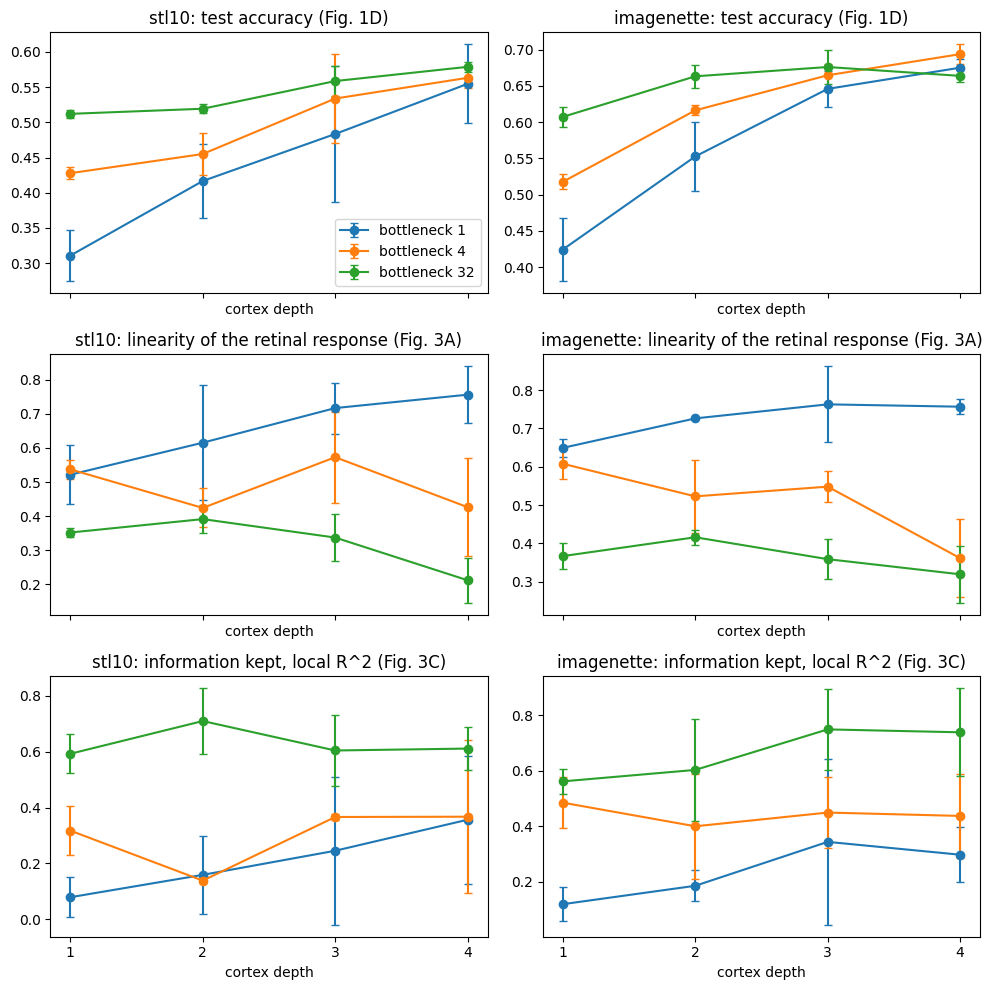

,measure,dataset,bottleneck,depth 1,depth 2,depth 3,depth 4,slope
0,test_acc,stl10,1,0.311,0.417,0.483,0.555,0.080
1,test_acc,stl10,4,0.428,0.455,0.534,0.563,0.049
2,test_acc,stl10,32,0.512,0.519,0.559,0.579,0.024
3,test_acc,imagenette,1,0.424,0.553,0.646,0.675,0.085
4,test_acc,imagenette,4,0.518,0.616,0.665,0.694,0.058
5,test_acc,imagenette,32,0.607,0.663,0.676,0.664,0.018
6,linearity,stl10,1,0.522,0.616,0.717,0.756,0.081
7,linearity,stl10,4,0.537,0.424,0.573,0.426,-0.018
8,linearity,stl10,32,0.352,0.391,0.337,0.212,-0.047
9,linearity,imagenette,1,0.649,0.726,0.763,0.757,0.036


cells with a positive slope against cortex depth (of 6 = 2 datasets x 3 bottlenecks): {'info_r2': 4, 'linearity': 2, 'test_acc': 6}


test_acc         linearity           info_r2       
dataset    imagenette  stl10 imagenette  stl10 imagenette  stl10
bottleneck                                                      
1               0.553  0.417      0.726  0.616      0.186  0.159
2               0.588  0.462      0.582  0.599      0.179  0.189
4               0.616  0.455      0.523  0.424      0.400  0.139
8               0.624  0.496      0.551  0.431      0.391  0.324
16              0.643  0.493      0.448  0.365      0.600  0.374
32              0.663  0.519      0.416  0.391      0.603  0.709

osi_retina_median  osi_cortex1_median  n_live_retina  \
dataset    bottleneck                                                         
imagenette 1                        1.47                3.32           1.00   
           2                        2.51                3.38           2.00   
           4                        4.15                3.75           3.67   
           8                        3.53                2.69           7.00   
           16                       2.69                2.68          14.33   
           32                       3.60                2.55          27.33   
stl10      1                        2.90                5.25           1.00   
           2                        3.70                3.28           2.00   
           4                        2.71                2.89           3.67   
           8                        3.43                2.85           6.33   
           16                       2.80                2.79          12.67   
           32                       2.74                2.37          24.33   

                       n_live_cortex1  
dataset    bottleneck                  
imagenette 1                     32.0  
           2                     32.0  
           4                     32.0  
           8                     32.0  
           16                    32.0  
           32                    32.0  
stl10      1                     32.0  
           2                     32.0  
           4                     32.0  
           8                     32.0  
           16                    32.0  
           32                    32.0

first cortical layer more oriented than the retina (median OSI) in 4 of 12 dataset x bottleneck cells


In [20]:
# Analysis of the depth grid and of the checkpoint measures: accuracy (Fig. 1D), linearity (Fig. 3A), information (Fig. 3C), OSI of the first cortical layer.
dg = pd.read_csv(DEPTH_CSV)
cols = ['dataset', 'bottleneck', 'retina_layers', 'cortex_layers', 'seed', 'test_acc']
acc_d = pd.concat([df[df.retina_layers == 2][cols], dg[cols]])  # sweep (depth 2, and 4 at bottleneck 2 and 16) + depth grid; df already holds the reruns
lin = pd.read_csv(LIN_CSV)
lin = lin[lin.retina_layers == 2].merge(acc_d, on=['dataset', 'bottleneck', 'retina_layers', 'cortex_layers', 'seed'])
BN3, DEPTHS = [1, 4, 32], [1, 2, 3, 4]
measures = {'test_acc': 'test accuracy (Fig. 1D)', 'linearity': 'linearity of the retinal response (Fig. 3A)', 'info_r2': 'information kept, local R^2 (Fig. 3C)'}

fig, axes = plt.subplots(3, 2, figsize=(10, 10), sharex=True)
for r, (m, title) in enumerate(measures.items()):
    for c, ds in enumerate(DATASETS):
        for b in BN3:
            g = lin[(lin.dataset == ds) & (lin.bottleneck == b)].groupby('cortex_layers')[m].agg(['mean', 'std']).reindex(DEPTHS)
            axes[r, c].errorbar(g.index, g['mean'], g['std'], marker='o', capsize=3, label=f'bottleneck {b}')
        axes[r, c].set(title=f'{ds}: {title}', xticks=DEPTHS)
        axes[r, c].set_xlabel('cortex depth')
axes[0, 0].legend()
plt.tight_layout()
plt.show()

# means over seeds, and the sign of the trend with depth at each bottleneck (least-squares slope over the available depths)
rows = []
for m in measures:
    for ds in DATASETS:
        for b in BN3:
            g = lin[(lin.dataset == ds) & (lin.bottleneck == b)].groupby('cortex_layers')[m].mean().reindex(DEPTHS)
            rows.append(dict(measure=m, dataset=ds, bottleneck=b, **{f'depth {d}': g[d] for d in DEPTHS}, slope=np.polyfit(DEPTHS, g.values, 1)[0]))
trend = pd.DataFrame(rows).round(3)
display(trend)
print('cells with a positive slope against cortex depth (of 6 = 2 datasets x 3 bottlenecks):', trend.groupby('measure').slope.apply(lambda s: int((s > 0).sum())).to_dict())

# dependence on the bottleneck width at cortex depth 2 (all six widths)
w = lin[lin.cortex_layers == 2].groupby(['dataset', 'bottleneck'])[['test_acc', 'linearity', 'info_r2']].mean().round(3).unstack('dataset')
display(w)

# OSI of the first cortical layer against the retina output, cortex depth 2
osi = lin[lin.cortex_layers == 2].groupby(['dataset', 'bottleneck'])[['osi_retina_median', 'osi_cortex1_median', 'n_live_retina', 'n_live_cortex1']].mean().round(2)
display(osi)
print('first cortical layer more oriented than the retina (median OSI) in', int((osi.osi_cortex1_median > osi.osi_retina_median).sum()), 'of', len(osi), 'dataset x bottleneck cells')

### Depth grid, linearity and first cortical layer: findings

Cortex depth 1-4 at bottleneck 1, 4, 32 (depth 2 and the widths from the main sweep), 3 seeds, both datasets; means over seeds. 9 of the 54 new runs collapsed at the first attempt (7 of them at bottleneck 1 with cortex depth 3 or 4) and were retrained with lr / 3, so part of the deep bottleneck-1 accuracies comes from reruns.

- **Accuracy (paper claim iii): reproduced.** Accuracy increases with the cortex depth in all 6 dataset x bottleneck cells (bottleneck 1, depth 1 to 4: STL-10 0.311 -> 0.555, Imagenette 0.424 -> 0.675; bottleneck 32: 0.512 -> 0.579 and 0.607 -> 0.664, with the Imagenette maximum at depth 3), and with the bottleneck width at depth 2 (Imagenette 0.553 -> 0.663, STL-10 0.417 -> 0.519, with small non-monotonic steps).
- **Linearity (claim ii), prediction (a) only partly confirmed.** Linearity increases with the cortex depth at bottleneck 1 on both datasets (STL-10 0.52 -> 0.76, Imagenette 0.65 -> 0.76 from depth 1 to 4), which is the case the paper highlights (about 0.9 variance explained at bottleneck 1 with the deepest cortex), but not at bottleneck 4 (slope -0.02 and -0.07) and 32 (-0.05 and -0.02), where it is flat or non-monotonic with a maximum at depth 2 (the paper reports a maximum at depth 1 without bottleneck). A deeper cortex also leaves fewer live retina channels at width 32 (STL-10: 27 at depth 1, 12.7 at depth 4), so these averages are over a shrinking set of channels. **Prediction (b), linearity decreases as the bottleneck widens, is confirmed** at depth 2 (Imagenette 0.73 at bottleneck 1 -> 0.42 at 32, STL-10 0.62 -> 0.39, with small non-monotonic steps), as in the paper (Fig. 3A).
- **Information (prediction c) partly confirmed.** The local reconstruction R^2 increases with the cortex depth in 4 of the 6 cells (bottleneck 1 on both datasets, e.g. STL-10 0.08 -> 0.36; STL-10 bottleneck 4; Imagenette bottleneck 32) and is flat in the other two. It also grows with the width, as it must, since more channels carry more information.
- **First cortical layer (prediction d): confirmed at narrow bottlenecks.** At bottleneck 1-4 the first cortical layer is more oriented than the retina in 4 of 6 dataset x bottleneck cells (bottleneck 1: median OSI 3.3 vs 1.5 on Imagenette, 5.3 vs 2.9 on STL-10), with values around the 3.05 of the paper; at wider bottlenecks the retina is itself oriented and there is no difference (4 of 12 cells overall).

## Discussion

For each hypothesis: expected outcome, observed outcome, explanation of any mismatch with the paper. Numbers: mean over 3 seeds, 96x96 grayscale, retina depth 2 and cortex depth 2 unless stated; shares are fractions of retina output channels by label (702 channels in total: 316 `other`, 270 `oriented`, 94 `dead`, 22 `center-surround`). The OSI averaged over non-dead channels is 3.3 (median 2.5); the paper reports 1.56 for the retina output (bottleneck 1, cortex depth 2), 3.05 for the first cortical layer and 1.97 for random filters. All filter numbers use the corrected RF probe (input centred as in the forward pass).

**Summary against the three claims of the paper** (mapping in the introduction). (i) *A narrow bottleneck gives center-surround retinal RFs and oriented RFs in the first cortical layer:* partly. At the paper's headline configuration (bottleneck 1, cortex depth 2) the retinal OSI is 1.47 on Imagenette (paper 1.56) but 2.90 on STL-10, and in the CIFAR-10 control 1.60; the first cortical layer is more oriented than the retina at bottleneck 1-4 in 4 of 6 cells (OSI 3.3-5.3, paper 3.05). (ii) *Cortex depth changes the linearity of the retina:* only at bottleneck 1 (linearity 0.52-0.65 -> 0.76 from depth 1 to 4); linearity decreases with the bottleneck width as in the paper. (iii) *Accuracy increases with the width and the depth:* reproduced. The hypotheses 1 and 2 of this notebook are stricter than claims (i) and (ii) and are discussed below.

- **H1 (narrow bottleneck + deep cortex -> center-surround retina filters): not reproduced as stated; the paper's headline value appears on one dataset only.**
  - Only 22 of 702 channels (3.1%) are labelled center-surround, and in the configuration of the hypothesis (bottleneck 2, cortex 4) it is 1 of 6 channels on each dataset. There 3 of 6 channels are `oriented` on both datasets, and the median OSI of the live channels is 2.7 (STL-10, 5 live channels) and 2.0 (Imagenette, 6 live channels), against 1.56 for the retina and 3.05 for the first cortical layer in the paper; 2 of 5 and 3 of 6 live channels are isotropic (OSI < 2). Counts and not percentages are given for these cells because a cell has only 6 channels (3 seeds x 2).
  - At the paper's headline configuration (bottleneck 1, cortex 2) the live retina channels have OSI 1.22, 1.51 and 1.69 on Imagenette (mean 1.47, close to the 1.56 of the paper) but 1.84, 3.23 and 3.62 on STL-10 (mean 2.90). With 3 channels per dataset this is suggestive only.
  - The conclusion does not rest on the DoG/Gabor labels alone (see "Retina filters without labels" above). Over the 608 live channels the median OSI is 2.5, against 1.56 in the paper, and 37% have OSI < 2. The `center-surround` label is conservative: it needs a DoG fit with R^2 >= 0.5 that is not worse than the Gabor fit, so isotropic filters with a poor DoG fit end up in `other` (median OSI 1.8), and the 22 `center-surround` channels have DoG and Gabor R^2 within 0.10 of each other, i.e. they are low-confidence labels. In OSI terms (cortex 2) the narrow-bottleneck effect appears on Imagenette (6 of 9 live channels at bottleneck 1-2 have OSI < 2, against 32 of 125 at bottleneck 16-32) but not on STL-10 (2 of 9 against 37 of 111), always on 9 channels at the narrow end.
  - Why is only partly known. A positive control in the paper's own setup (section "Positive control: the paper's own setup") reproduces the paper's headline value (bottleneck 1, cortex 2: mean OSI 1.60 against 1.56 +- 0.22), but its networks are mostly dead and few channels are live, so it cannot say which difference between the two setups matters. Differences that could matter, none of which was isolated: far less training data (4.5k and 8.5k images instead of 50k), 96x96 instead of 32x32 inputs (the same 9x9 kernels cover a much smaller part of the scene; a 32x32 pilot also gave no center-surround filters), global average pooling plus a linear classifier instead of a flattened dense layer, 3 seeds instead of 10, and our RF probe (gradient averaged over natural images instead of a blank image, which leaves 77% of the channels silent).
- **H2 (wide bottleneck or shallow cortex -> oriented retina filters): partly supported as worded; it is not a claim of the paper.**
  - Wide bottleneck: bottleneck 32 has 49/96 (STL-10) and 54/96 (Imagenette) oriented channels (median OSI 2.8 and 3.6). Narrow bottlenecks (1-2, cortex 2) are *more* oriented on STL-10 (7 of 9 channels) and less on Imagenette (3 of 9), so the bottleneck effect on filter geometry is absent on STL-10 and present only on Imagenette.
  - Shallow cortex: with the bottleneck fixed, cortex 2 has more oriented channels than cortex 4 in 3 of 4 comparisons and a tie in the fourth (bottleneck 2: STL-10 5/6 vs 3/6, Imagenette 3/6 vs 3/6; bottleneck 16: STL-10 22/48 vs 14/48, Imagenette 28/48 vs 16/48), consistent with hypothesis 2 as worded. In OSI terms the effect is small (channels with OSI < 2, bottleneck 2: STL-10 1/6 vs 2/5, Imagenette 3/6 vs 3/6; bottleneck 16: STL-10 14/38 vs 11/27, Imagenette 14/43 vs 18/38). This is not a claim of the paper: it reports that the retinal RF geometry does not depend qualitatively on the cortex depth (for depth of at least 1) and that depth changes the linearity of the retinal response, which is not measured in this section.
  - Retina depth 1: most filters are `other` (bottleneck 2: 6/6 on both datasets; bottleneck 16: 39/48 on STL-10, 32/48 on Imagenette); the 9x9 receptive field is small for the DoG/Gabor fits, so this label is not reliable.
- **H3 (accuracy drops little while the bottleneck stays above a threshold): not confirmed as a threshold; accuracy decreases gradually.**
  - Test accuracy for bottleneck 1, 2, 4, 8, 16, 32: STL-10 0.417, 0.462, 0.455, 0.496, 0.493, 0.519; Imagenette 0.553, 0.588, 0.616, 0.624, 0.643, 0.663. Doubling the bottleneck changes accuracy by -1 to +4.5 points step by step (the steps 2 to 4 and 8 to 16 are within noise), with no knee; overall, going from 32 to 1 channel costs about 10 points on both datasets. A "within 1 point of the widest" rule selects only the widest bottleneck on both datasets.
  - The paper also reports accuracy increasing with both bottleneck width and cortex depth; both parts are reproduced: accuracy increases with the cortex depth in all 6 cells of the depth grid (bottleneck 1, depth 1 to 4: STL-10 0.31 -> 0.56, Imagenette 0.42 -> 0.68) and with the width at depth 2 (cortex 4 vs 2 gives +12 points on STL-10 and +9 on Imagenette at bottleneck 2, +6 and +4 at bottleneck 16).

### Limitations

- Absolute accuracy is low (0.42-0.71) because of the small training sets and the small network, and 13% of the retina channels (94 of 702) are dead (never active at the image centre), so the analysed filters are a subset of the trained ones.
- Training recipe: the first sweep used PyTorch defaults with Adam and produced dead and noisy filters; the recipe was then fixed to the paper's (Glorot, RMSProp, lr 1e-3, batch 32) after a validation-only pilot that also looked at filter health. 3 of 72 runs collapsed to chance level and were retrained once with lr / 3 (rule fixed after the sweep, raw results kept in `results.csv`). All reported numbers use the rerun values for those three runs.
- Filter labels depend on thresholds set on synthetic filters (100% accuracy there) and not validated against human labels on learned filters, and the `center-surround` label is strict (37% of the live channels have OSI < 2, 3% of all channels are labelled center-surround); the RF probe differs from the paper's blank-image gradient (77% of the channels are silent on a flat image). An earlier version of the analysis probed the retina without the input centring (a bug found when re-reading the paper); it changed the counts (center-surround 11 -> 22, dead 137 -> 94) but not the picture, and its outputs are kept in `results/*_rawprobe.csv`.
- Positive control: with the paper's architecture and recipe 67% of the retina channels are dead under the natural-image probe (149 of 222), 6 of 18 runs collapsed at the first attempt and accuracy is 0.56-0.67, so the control has 3-9 live channels at the cells that matter and its conclusions are tentative. The prediction and decision rule of the control were written following our hypothesis 1 (cortex 4), not the paper's headline configuration (cortex 2).
- The depth grid has 9 collapsed first attempts (7 at bottleneck 1), retrained with lr / 3; linearity and information are measured on patches of 250-1,000 images and averaged over the live channels only; the information measure is a local proxy of the paper's whole-image reconstruction; depth 0, class separability, the untied retina, the LGN network, simple/complex cells and local normalisation are not reproduced.
- Only 3 seeds (paper: 10), one architecture family, no ablation on kernel size or on the number of cortex channels.